In [17]:
import os, glob, random, zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


In [18]:
import os, zipfile

EXTS = (".jpg", ".jpeg", ".png")
zip_path = "/content/data-temp.zip"
extract_to = "/content/data-temp"

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("/content")          # creates /content/data-temp (or whatever is inside the zip)
elif not os.path.isdir(extract_to):
    raise FileNotFoundError("Upload data-temp.zip to /content first")

# find the two class folders wherever they sit inside data-temp
RAW = {}
for root, dirs, _ in os.walk("/content/data-temp"):
    for d in dirs:
        if d.lower() in ("functional", "damaged"):
            RAW[d.lower()] = os.path.join(root, d)

print("Found classes:", list(RAW))
for cls, path in RAW.items():
    n = len([f for f in os.listdir(path) if f.lower().endswith(EXTS)])
    print(f"{cls}: {n} images at {path}")

Found classes: ['functional', 'damaged']
functional: 138 images at /content/data-temp/functional
damaged: 20 images at /content/data-temp/damaged


In [19]:
!pip install -q pillow pillow-avif-plugin

In [20]:
from PIL import Image
import pillow_avif            # enables .avif support
import shutil, os

shutil.rmtree("/content/clean", ignore_errors=True)
ALL_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".jfif", ".avif", ".gif", ".tiff")

CLEAN = {}
for cls, folder in RAW.items():
    out_dir = f"/content/clean/{cls}"
    os.makedirs(out_dir, exist_ok=True)
    files = []
    for root, _, names in os.walk(folder):
        for n in names:
            if n.lower().endswith(ALL_EXTS):
                files.append(os.path.join(root, n))
    files.sort()

    ok, failed = 0, []
    for p in files:
        try:
            with Image.open(p) as im:
                im = im.convert("RGB")          # drops transparency, fixes odd modes
                ok += 1
                im.save(f"{out_dir}/{cls}_{ok:03d}.jpg", "JPEG", quality=95)
        except Exception as e:
            failed.append((os.path.basename(p), str(e)[:60]))

    CLEAN[cls] = out_dir
    print(f"{cls}: {len(files)} found, {ok} converted, {len(failed)} failed")
    for f in failed[:10]:
        print("   failed:", f)

functional: 138 found, 138 converted, 0 failed
damaged: 138 found, 138 converted, 0 failed


damaged: found 138 images
  damaged/train: 110 saved
  damaged/val: 28 saved
functional: found 138 images
  functional/train: 110 saved
  functional/val: 28 saved

Train array: (220, 128, 128, 3) | Val array: (56, 128, 128, 3)
Pixel range after normalization: -1.0 to 1.0


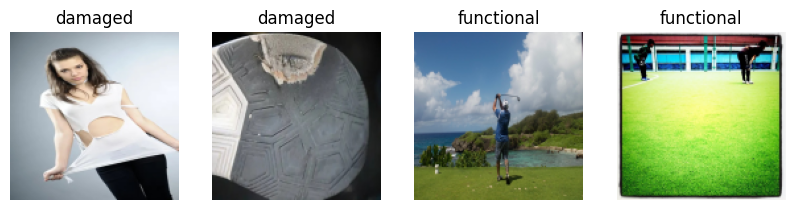

In [16]:
import shutil
shutil.rmtree("/content/data", ignore_errors=True)   # clears the old broken split

IMG_SIZE = 128
MEAN = np.array([0.5, 0.5, 0.5], dtype=np.float32)
STD  = np.array([0.5, 0.5, 0.5], dtype=np.float32)
EXTS = (".jpg", ".jpeg", ".png")

def preprocess_image(path, size=IMG_SIZE):
    """Read an image, resize it, and normalize it."""
    img = cv2.imread(path)
    if img is None:
        return None, None
    resized = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    scaled = rgb.astype(np.float32) / 255.0
    normalized = (scaled - MEAN) / STD
    return resized, normalized

def list_images(folder):
    found = []
    for root, _, names in os.walk(folder):
        for n in names:
            if n.lower().endswith(EXTS):
                found.append(os.path.join(root, n))
    return sorted(found)

def build_dataset(raw_dirs, out_root="/content/data", split=0.8, size=IMG_SIZE):
    X = {"train": [], "val": []}
    y = {"train": [], "val": []}
    for label, cls in enumerate(sorted(raw_dirs)):
        files = list_images(raw_dirs[cls])
        print(f"{cls}: found {len(files)} images")
        random.shuffle(files)
        cut = int(split * len(files))
        for subset, paths in {"train": files[:cut], "val": files[cut:]}.items():
            out_dir = os.path.join(out_root, subset, cls)
            os.makedirs(out_dir, exist_ok=True)
            n = 0
            for p in paths:
                resized, normalized = preprocess_image(p, size)
                if resized is None:
                    print("  could not read:", p)
                    continue
                n += 1
                cv2.imwrite(os.path.join(out_dir, f"{cls}_{subset}_{n:03d}.jpg"), resized)
                X[subset].append(normalized)
                y[subset].append(label)
            print(f"  {cls}/{subset}: {n} saved")
    return {k: np.array(v) for k, v in X.items()}, {k: np.array(v) for k, v in y.items()}

# the key change: build from CLEAN (the converted jpgs), not RAW
X, y = build_dataset(CLEAN)

print("\nTrain array:", X["train"].shape, "| Val array:", X["val"].shape)
print("Pixel range after normalization:", X["train"].min(), "to", X["train"].max())

# quick visual check
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, i in zip(axes, [0, 1, -1, -2]):
    ax.imshow((X["train"][i] * 0.5 + 0.5).clip(0, 1))
    ax.set_title("functional" if y["train"][i] else "damaged")
    ax.axis("off")
plt.show()

In [21]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

# same normalization as preprocess_image (mean 0.5, std 0.5)
norm = transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
train_tf = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.ToTensor(), norm])
val_tf   = transforms.Compose([transforms.ToTensor(), norm])

train_ds = datasets.ImageFolder("/content/data/train", transform=train_tf)
val_ds   = datasets.ImageFolder("/content/data/val", transform=val_tf)

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl   = DataLoader(val_ds, batch_size=16, shuffle=False)

print("Classes:", train_ds.class_to_idx)
print("Train:", len(train_ds), "| Val:", len(val_ds))

Using: cpu
Classes: {'damaged': 0, 'functional': 1}
Train: 220 | Val: 56


In [22]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        # three conv blocks: each one detects patterns, then halves the image size
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),   # 128x128 -> 16 channels
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 64x64

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 32x32

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 16x16
        )
        # classifier turns the feature maps into 2 scores (damaged / functional)
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # 64 * 16 * 16 = 16384 values
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.5),                              # reduces overfitting on a small dataset
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = BaselineCNN().to(device)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Parameters: 2121122


In [23]:
x, y = next(iter(train_dl))
out = model(x.to(device))
print("Input batch:", x.shape)     # expect [16, 3, 128, 128]
print("Output:", out.shape)        # expect [16, 2]

Input batch: torch.Size([16, 3, 128, 128])
Output: torch.Size([16, 2])


In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 20

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    # ---- train ----
    model.train()
    train_loss, train_correct = 0.0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x.size(0)
        train_correct += (out.argmax(1) == y).sum().item()

    # ---- validate ----
    model.eval()
    val_loss, val_correct = 0.0, 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            val_loss += criterion(out, y).item() * x.size(0)
            val_correct += (out.argmax(1) == y).sum().item()

    history["train_loss"].append(train_loss / len(train_ds))
    history["val_loss"].append(val_loss / len(val_ds))
    history["train_acc"].append(train_correct / len(train_ds))
    history["val_acc"].append(val_correct / len(val_ds))

    # keep the weights from the best epoch
    if history["val_acc"][-1] > best_val_acc:
        best_val_acc = history["val_acc"][-1]
        torch.save(model.state_dict(), "baseline_cnn_best.pth")

    print(f"Epoch {epoch:2d}/{EPOCHS} | "
          f"train loss {history['train_loss'][-1]:.4f} acc {history['train_acc'][-1]:.3f} | "
          f"val loss {history['val_loss'][-1]:.4f} acc {history['val_acc'][-1]:.3f}")

# also save the final-epoch weights
torch.save(model.state_dict(), "baseline_cnn.pth")

print(f"\nFinal validation accuracy: {history['val_acc'][-1]:.3f}")
print(f"Best validation accuracy:  {best_val_acc:.3f}")

Epoch  1/20 | train loss 0.6995 acc 0.514 | val loss 0.6499 acc 0.661
Epoch  2/20 | train loss 0.6067 acc 0.641 | val loss 0.7148 acc 0.554
Epoch  3/20 | train loss 0.6173 acc 0.636 | val loss 0.6010 acc 0.679
Epoch  4/20 | train loss 0.6086 acc 0.673 | val loss 0.5988 acc 0.643
Epoch  5/20 | train loss 0.5609 acc 0.695 | val loss 0.6024 acc 0.679
Epoch  6/20 | train loss 0.5111 acc 0.755 | val loss 0.5494 acc 0.696
Epoch  7/20 | train loss 0.5099 acc 0.750 | val loss 0.6423 acc 0.643
Epoch  8/20 | train loss 0.5013 acc 0.755 | val loss 0.5892 acc 0.696
Epoch  9/20 | train loss 0.4696 acc 0.786 | val loss 0.6090 acc 0.661
Epoch 10/20 | train loss 0.4366 acc 0.786 | val loss 0.6997 acc 0.643
Epoch 11/20 | train loss 0.3958 acc 0.814 | val loss 0.6771 acc 0.696
Epoch 12/20 | train loss 0.3813 acc 0.805 | val loss 0.6772 acc 0.661
Epoch 13/20 | train loss 0.3549 acc 0.823 | val loss 0.9950 acc 0.589
Epoch 14/20 | train loss 0.3279 acc 0.832 | val loss 0.7569 acc 0.679
Epoch 15/20 | train 

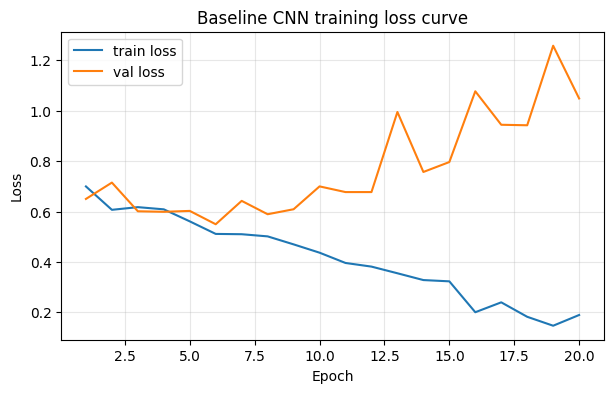

In [25]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), history["train_loss"], label="train loss")
plt.plot(range(1, EPOCHS + 1), history["val_loss"], label="val loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Baseline CNN training loss curve")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
from google.colab import files
files.download("baseline_cnn.pth")
files.download("baseline_cnn_best.pth")
files.download("loss_curve.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
!zip -rq data.zip /content/data
from google.colab import files
files.download("data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>